# Final Project — Enterprise Multi-Modal Data Visualization & Storytelling
## `final_visualizations.ipynb`

**Dataset:** *Sample – Superstore* (US retail, multi-channel sales over 4 years, 9,994 order lines + regional-manager and returns tables).
It contains every field type the project requires:

| Field type | Columns |
|---|---|
| Continuous | `Sales`, `Profit`, `Discount`, `Quantity` |
| Categorical | `Category`, `Sub-Category`, `Segment`, `Ship Mode`, `Region` |
| Temporal | `Order Date`, `Ship Date` |
| Geospatial | `State`, `City`, `Postal Code` |

**Business question:** *Sales keep growing, so why is profit margin so thin, and where is the company losing money?*

### Notebook structure
1. Environment setup & global style (graphical foundations)
2. Data acquisition, cleaning & missing-value imputation (Role 1)
3. Feature engineering (temporal, ratio and band features)
4. Distributions (histogram, KDE, box/violin)
5. Uncertainty & variability (95 % confidence intervals)
6. X–Y relationships (correlation heatmap, interactive scatter/bubble)
7. Proportions & geospatial views (treemap, choropleth)
8. Polar coordinates for cyclical data (seasonality)
9. Key statistical findings for the story arc
10. Asset export (PNG/SVG/HTML) + dashboard-ready dataset

## 1. Environment setup & global style

In [1]:
# Core libraries required by the project brief
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

# ---- Paths --------------------------------------------------------------
RAW_PATH   = "../data/raw_superstore.csv"     # original download (untouched)
CLEAN_PATH = "../data/clean_superstore.csv"   # output consumed by the BI dashboard
ASSETS     = "../assets"                       # exported PNG / SVG / HTML
os.makedirs(ASSETS, exist_ok=True)

# ---- Global visual standards (graphical foundations) ----------------------
# * Decluttering: no top/right spines, no gridlines, light axis colour.
# * Colour-blind safe palettes:
#     - qualitative  -> seaborn "colorblind" (for discrete categories)
#     - sequential   -> "viridis"            (for ordered magnitudes)
#     - diverging    -> "RdBu"               (for profit/loss around 0)
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "axes.edgecolor": "#888888",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "figure.dpi": 110,
    "savefig.dpi": 300,          # high-resolution static exports
    "savefig.bbox": "tight",
})
QUAL = sns.color_palette("colorblind")
SEQ = "viridis"
DIV = "RdBu"
pio.templates.default = "simple_white"

def save(fig, name):
    """Export a Matplotlib figure as high-res PNG and vector SVG."""
    fig.savefig(f"{ASSETS}/{name}.png")
    fig.savefig(f"{ASSETS}/{name}.svg")

print("Libraries loaded — pandas", pd.__version__, "| seaborn", sns.__version__)

Libraries loaded — pandas 3.0.6 | seaborn 0.13.2


## 2. Data acquisition, cleaning & imputation  *(Role 1 — Data Architect & Wrangler)*
The raw file was downloaded from a public GitHub mirror of Tableau's *Sample – Superstore* dataset.

In [2]:
# latin1 encoding is needed because some product names contain special characters
raw = pd.read_csv(RAW_PATH, encoding="latin1")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [3]:
# ---- Data-quality audit ---------------------------------------------------
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
})
print("Fully empty rows:", raw.isna().all(axis=1).sum())
print("Exact duplicate rows:", raw.duplicated().sum())
audit

Fully empty rows: 0
Exact duplicate rows: 504


,dtype,missing,missing_%
Row ID,str,0,0.00
Order ID,str,0,0.00
Order Date,str,806,7.46
Ship Date,str,806,7.46
Ship Mode,str,806,7.46
Customer ID,str,806,7.46
Customer Name,str,806,7.46
Segment,str,806,7.46
Country,str,806,7.46
City,str,806,7.46


In [4]:
raw = raw.dropna(how="all")      # 1) remove fully empty rows (blank lines in the CSV export)

# 2) Schema structuring. The audit shows the CSV is really THREE Excel sheets stacked together:
#    * rows with a numeric Row ID           -> Orders fact table
#    * a "Person | Region" block            -> People dimension (regional manager per region)
#    * a "Returned | Order ID" block        -> Returns table (orders that were sent back)
is_order = raw["Row ID"].astype(str).str.isdigit()
extra = raw.loc[~is_order, ["Row ID", "Order ID"]]
print(extra.head(8))

people = (extra[extra["Order ID"].isin(["West", "East", "Central", "South"])]
          .rename(columns={"Row ID": "Regional Manager", "Order ID": "Region"}))
returns = (extra[extra["Row ID"] == "Yes"]
           .rename(columns={"Row ID": "Returned"})
           .drop_duplicates("Order ID"))           # one flag per order
df = raw.loc[is_order].copy()
print(f"Orders: {len(df):,} | People: {len(people)} | Returned orders: {len(returns):,}")

# 3) Remove exact duplicate rows in the fact table, if any
df = df.drop_duplicates()

# 4) Star-schema joins: attach the regional manager and the return flag to every order line
df = df.merge(people, on="Region", how="left")
df["Returned"] = df["Order ID"].isin(returns["Order ID"])

# 5) Type casting: temporal fields -> datetime, Row ID -> int
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  format="%m/%d/%Y")
df["Row ID"] = df["Row ID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)

print("Clean shape:", df.shape)
print("Remaining missing values:\n", df.isna().sum()[df.isna().sum() > 0])

                  Row ID        Order ID
9994              Person          Region
9995       Anna Andreadi            West
9996         Chuck Magee            East
9997      Kelly Williams         Central
9998   Cassandra Brandow           South
9999            Returned        Order ID
10000                Yes  CA-2015-100762
10001                Yes  CA-2015-100762
Orders: 9,994 | People: 4 | Returned orders: 296
Clean shape: (9994, 23)
Remaining missing values:
 Postal Code    11
dtype: int64


In [5]:
# 6) Missing-value imputation: Postal Code
# Inspect which rows are missing a postal code
missing_zip = df[df["Postal Code"].isna()][["City", "State"]].value_counts()
print(missing_zip)

# All missing ZIPs belong to Burlington, Vermont. Imputation strategy:
#   a) use the most frequent ZIP of the same City+State inside the dataset (mode imputation by group)
#   b) if the city never appears with a ZIP, fall back to its official ZIP (Burlington, VT = 05401)
mode_zip = (df.dropna(subset=["Postal Code"])
              .groupby(["City", "State"])["Postal Code"]
              .agg(lambda s: s.mode().iloc[0]))
df["Postal Code"] = df.apply(
    lambda r: mode_zip.get((r["City"], r["State"]), np.nan) if pd.isna(r["Postal Code"]) else r["Postal Code"],
    axis=1)
df.loc[df["Postal Code"].isna() & (df["City"] == "Burlington") & (df["State"] == "Vermont"), "Postal Code"] = 5401

# ZIP codes are identifiers, not numbers -> 5-character zero-padded strings
df["Postal Code"] = df["Postal Code"].astype(int).astype(str).str.zfill(5)
assert df.isna().sum().sum() == 0, "There are still missing values!"
print("✔ No missing values left")

City        State  
Burlington  Vermont    11
Name: count, dtype: int64
✔ No missing values left


In [6]:
# 7) Sanity checks on continuous fields
assert (df["Sales"] > 0).all()
assert df["Discount"].between(0, 1).all()
assert (df["Ship Date"] >= df["Order Date"]).all()
df[["Sales", "Quantity", "Discount", "Profit"]].describe().round(2)

,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


## 3. Feature engineering (schema structuring)

In [7]:
# Temporal features
df["Year"]       = df["Order Date"].dt.year
df["Month"]      = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.strftime("%b")
df["YearMonth"]  = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Ship Days"]  = (df["Ship Date"] - df["Order Date"]).dt.days

# Ratio features
df["Profit Margin"] = df["Profit"] / df["Sales"]          # profit per $ sold
df["Unit Price"]    = df["Sales"] / df["Quantity"]
df["Is Loss"]       = df["Profit"] < 0

# Ordered categorical: discount band (used throughout the story)
bins   = [-0.01, 0, 0.2, 0.4, 1]
labels = ["0%", "1–20%", "21–40%", ">40%"]
df["Discount Band"] = pd.cut(df["Discount"], bins=bins, labels=labels)

# Geospatial: 2-letter state codes for choropleth maps
STATE_CODES = {
 'Alabama':'AL','Arizona':'AZ','Arkansas':'AR','California':'CA','Colorado':'CO','Connecticut':'CT',
 'Delaware':'DE','District of Columbia':'DC','Florida':'FL','Georgia':'GA','Idaho':'ID','Illinois':'IL',
 'Indiana':'IN','Iowa':'IA','Kansas':'KS','Kentucky':'KY','Louisiana':'LA','Maine':'ME','Maryland':'MD',
 'Massachusetts':'MA','Michigan':'MI','Minnesota':'MN','Mississippi':'MS','Missouri':'MO','Montana':'MT',
 'Nebraska':'NE','Nevada':'NV','New Hampshire':'NH','New Jersey':'NJ','New Mexico':'NM','New York':'NY',
 'North Carolina':'NC','North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA',
 'Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD','Tennessee':'TN','Texas':'TX','Utah':'UT',
 'Vermont':'VT','Virginia':'VA','Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY'}
df["State Code"] = df["State"].map(STATE_CODES)
assert df["State Code"].notna().all()

print(df.shape)
df[["Order Date", "Year", "Ship Days", "Profit Margin", "Discount Band", "State Code"]].head()

(9994, 33)


,Order Date,Year,Ship Days,Profit Margin,Discount Band,State Code
0,2017-11-08,2017,3,0.1600,0%,KY
1,2017-11-08,2017,3,0.3000,0%,KY
2,2017-06-12,2017,4,0.4700,0%,CA
3,2016-10-11,2016,7,-0.4000,>40%,FL
4,2016-10-11,2016,7,0.1125,1–20%,FL


## 4. Distributions — shape, spread and outliers
`Sales` is strongly right-skewed (a few very large orders), so a **log scale** is the correct axis choice
for an exponential range.

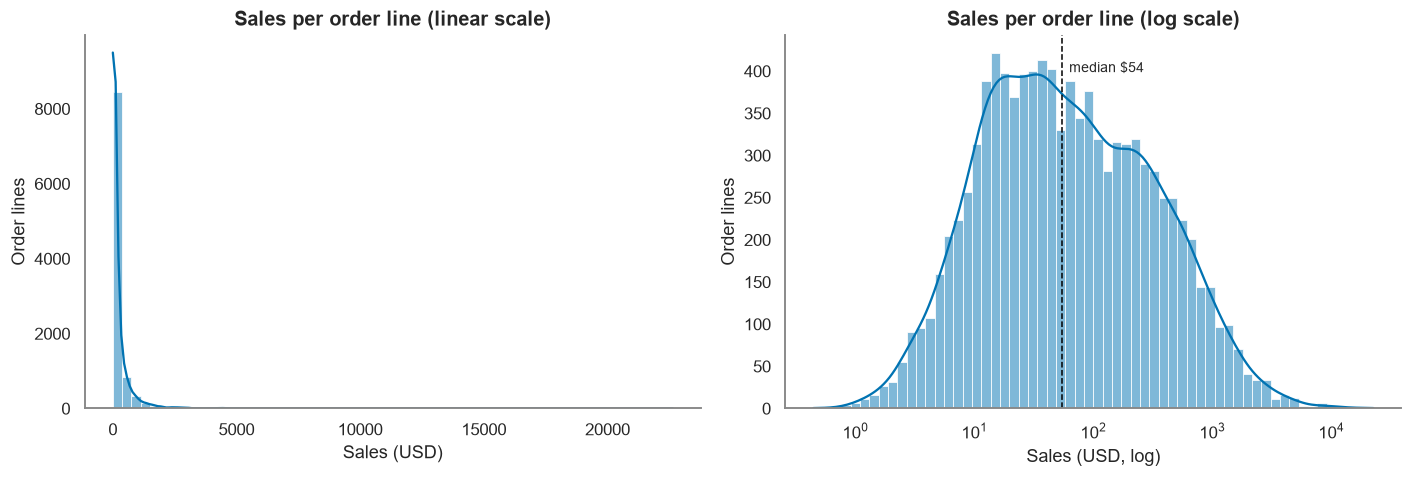

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) Histogram + KDE on a linear axis: the long tail hides the shape
sns.histplot(df["Sales"], bins=60, kde=True, color=QUAL[0], ax=axes[0])
axes[0].set(title="Sales per order line (linear scale)", xlabel="Sales (USD)", ylabel="Order lines")

# (b) Same data on a log axis: the real distribution becomes readable
sns.histplot(df["Sales"], bins=60, kde=True, log_scale=True, color=QUAL[0], ax=axes[1])
axes[1].set(title="Sales per order line (log scale)", xlabel="Sales (USD, log)", ylabel="Order lines")

median = df["Sales"].median()
axes[1].axvline(median, color="black", ls="--", lw=1)
axes[1].text(median * 1.15, axes[1].get_ylim()[1] * 0.9, f"median ${median:,.0f}", fontsize=9)
plt.tight_layout(); save(fig, "01_sales_distribution"); plt.show()

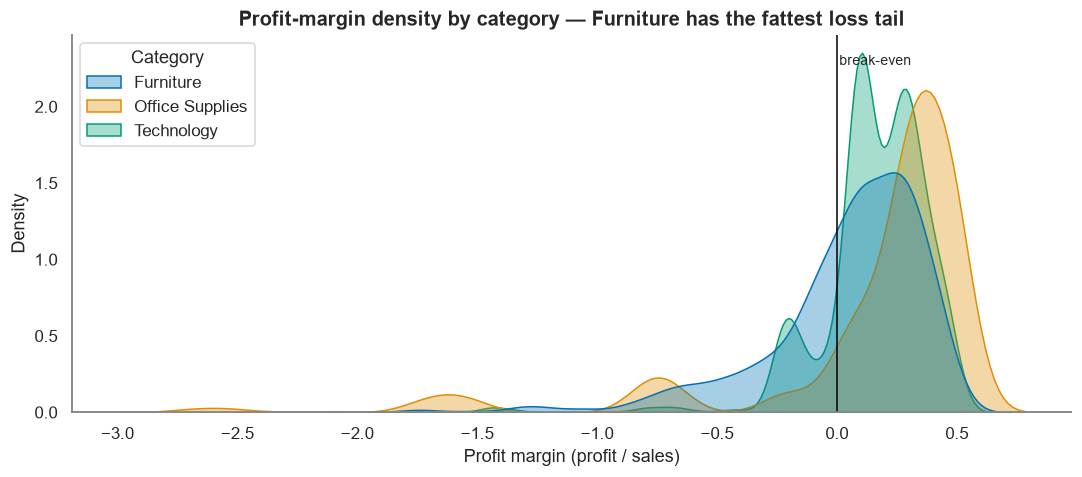

In [9]:
# KDE of profit margin by product category (qualitative, colour-blind palette)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.kdeplot(data=df, x="Profit Margin", hue="Category", fill=True, common_norm=False,
            alpha=.35, palette="colorblind", clip=(-3, 1), ax=ax)
ax.axvline(0, color="black", lw=1)
ax.text(0.01, ax.get_ylim()[1] * 0.92, "break-even", fontsize=9)
ax.set(title="Profit-margin density by category — Furniture has the fattest loss tail",
       xlabel="Profit margin (profit / sales)", ylabel="Density")
plt.tight_layout(); save(fig, "02_margin_kde_by_category"); plt.show()

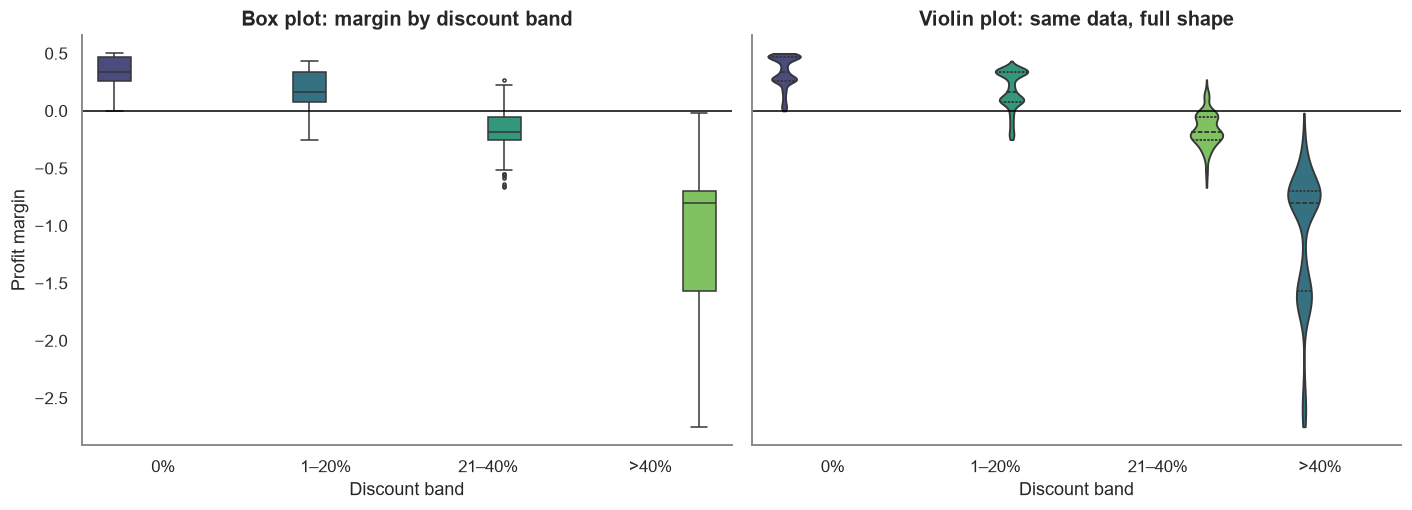

In [10]:
# Box plot + violin: profit margin by discount band (ordered categories, sequential palette)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
pal = sns.color_palette(SEQ, 4)

sns.boxplot(data=df, x="Discount Band", y="Profit Margin", hue="Discount Band", palette=pal,
            legend=False, fliersize=2, ax=axes[0])
axes[0].set(title="Box plot: margin by discount band", xlabel="Discount band", ylabel="Profit margin")

sns.violinplot(data=df, x="Discount Band", y="Profit Margin", hue="Discount Band", palette=pal,
               legend=False, cut=0, inner="quartile", ax=axes[1])
axes[1].set(title="Violin plot: same data, full shape", xlabel="Discount band", ylabel="")
for ax in axes:
    ax.axhline(0, color="black", lw=1)
plt.tight_layout(); save(fig, "03_margin_by_discount_box_violin"); plt.show()

## 5. Uncertainty & variability — 95 % confidence intervals
Error bars and CI bands communicate how much each average could move by chance (bootstrap, n=1000).

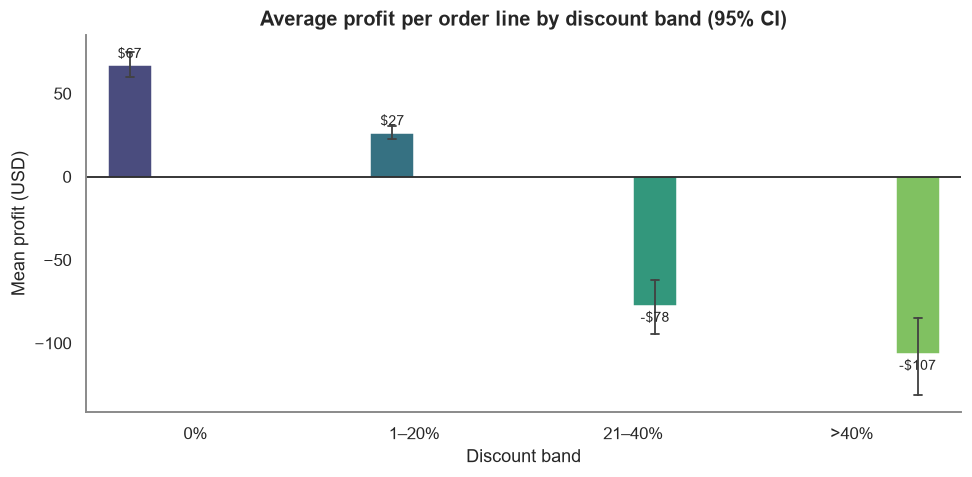

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
# Bar chart with a strict 0-baseline (bars always start at 0) + 95% CI error bars
sns.barplot(data=df, x="Discount Band", y="Profit", hue="Discount Band", palette=pal, legend=False,
            errorbar=("ci", 95), n_boot=1000, seed=42, capsize=.15, err_kws={"linewidth": 1.2}, ax=ax)
ax.axhline(0, color="black", lw=1)
ax.set(title="Average profit per order line by discount band (95% CI)",
       xlabel="Discount band", ylabel="Mean profit (USD)")
for c in ax.containers:
    ax.bar_label(c, fmt=lambda v: f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}", padding=3, fontsize=9)
plt.tight_layout(); save(fig, "04_profit_by_discount_ci"); plt.show()

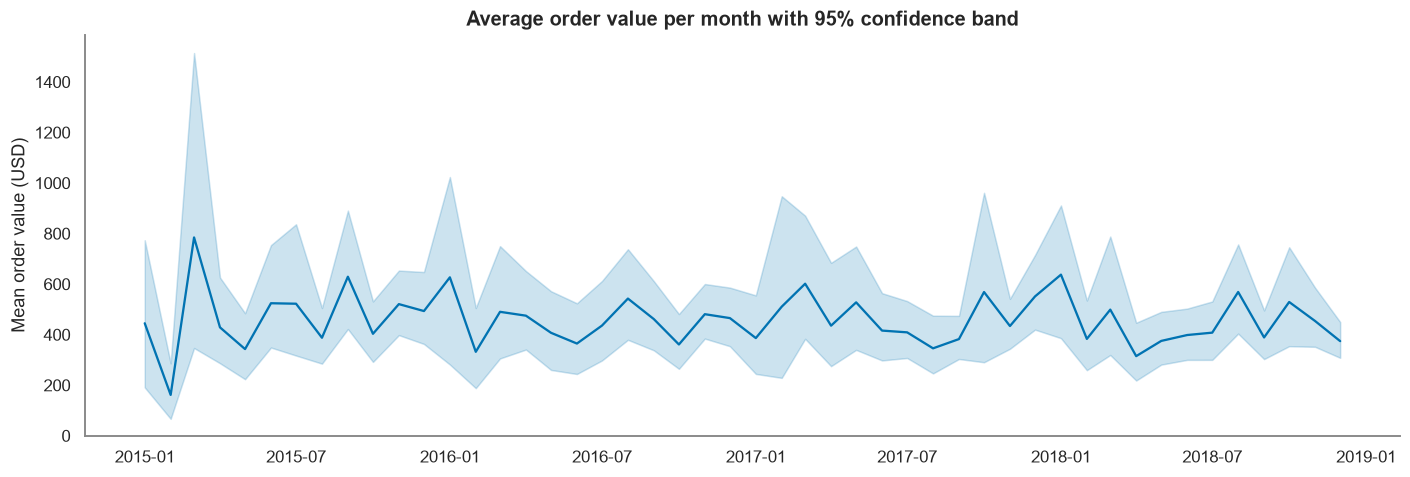

,Sales,Profit,Margin %,Sales growth %
Year,,,,
2015,484247.0,49544.0,10.0,NaN
2016,470533.0,61619.0,13.0,-3.0
2017,609206.0,81795.0,13.0,30.0
2018,733215.0,93439.0,13.0,20.0


In [12]:
# Monthly sales trend with a 95% CI band (variability across the order lines of each month)
monthly = df.groupby(["YearMonth", "Order ID"], as_index=False)["Sales"].sum()   # order-level sales
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.lineplot(data=monthly, x="YearMonth", y="Sales", estimator="mean", errorbar=("ci", 95),
             n_boot=500, seed=42, color=QUAL[0], ax=ax)
ax.set(title="Average order value per month with 95% confidence band",
       xlabel="", ylabel="Mean order value (USD)", ylim=(0, None))
plt.tight_layout(); save(fig, "05_order_value_trend_ci"); plt.show()

# Total sales and profit per year (for the story: growth vs margin)
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["Margin %"] = (yearly["Profit"] / yearly["Sales"] * 100).round(1)
yearly["Sales growth %"] = (yearly["Sales"].pct_change() * 100).round(1)
yearly.round(0)

## 6. X–Y relationships & correlation

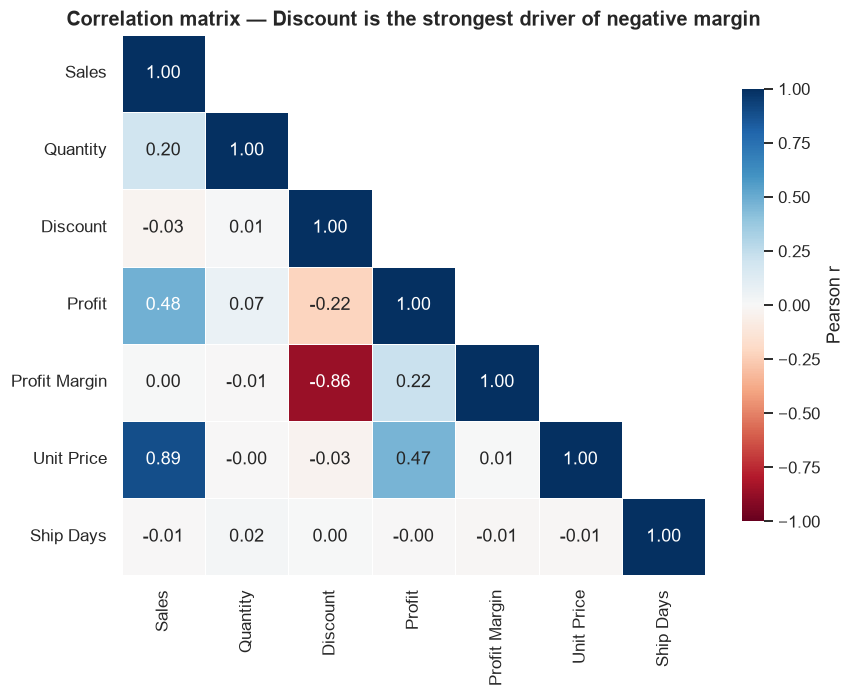

r(Discount, Profit Margin) = -0.864
Spearman r(Discount, Profit) = -0.543


In [13]:
# Correlation matrix (Pearson) of numeric variables — diverging palette centred at 0
num = df[["Sales", "Quantity", "Discount", "Profit", "Profit Margin", "Unit Price", "Ship Days"]]
corr = num.corr(method="pearson")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)      # hide the redundant upper triangle

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            linewidths=.5, cbar_kws={"label": "Pearson r", "shrink": .8}, ax=ax)
ax.set_title("Correlation matrix — Discount is the strongest driver of negative margin")
plt.tight_layout(); save(fig, "06_correlation_heatmap"); plt.show()

print("r(Discount, Profit Margin) =", round(corr.loc["Discount", "Profit Margin"], 3))
print("Spearman r(Discount, Profit) =", round(df["Discount"].corr(df["Profit"], method="spearman"), 3))

In [14]:
# Interactive bubble chart (Plotly): every sub-category positioned by Sales vs Profit
sub = (df.groupby(["Category", "Sub-Category"], as_index=False)
         .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
              Quantity=("Quantity", "sum"), AvgDiscount=("Discount", "mean")))
sub["Margin %"] = (sub["Profit"] / sub["Sales"] * 100).round(1)
sub["AvgDiscount %"] = (sub["AvgDiscount"] * 100).round(1)

fig = px.scatter(sub, x="Sales", y="Profit", size="Quantity", color="Margin %",
                 color_continuous_scale="RdBu", color_continuous_midpoint=0,
                 hover_name="Sub-Category", text="Sub-Category",
                 hover_data={"Category": True, "AvgDiscount %": True, "Quantity": True},
                 title="Sub-categories: Sales vs Profit (bubble = units, colour = margin)")
fig.update_traces(textposition="top center", textfont_size=10)
fig.add_hline(y=0, line_color="black", line_width=1)
fig.update_layout(height=550, xaxis_title="Total sales (USD)", yaxis_title="Total profit (USD)")
fig.write_html(f"{ASSETS}/07_subcategory_bubble.html", include_plotlyjs="cdn")
fig.show()

In [15]:
# Interactive scatter at order-line level: discount vs profit, coloured by category
fig = px.scatter(df, x="Discount", y="Profit", color="Category", opacity=.55,
                 color_discrete_sequence=px.colors.qualitative.Safe,
                 hover_data=["Sub-Category", "State", "Sales"],
                 title="Every order line: higher discounts push profit below zero")
fig.add_hline(y=0, line_color="black", line_width=1)
fig.update_layout(height=500, xaxis_tickformat=".0%")
fig.write_html(f"{ASSETS}/08_discount_vs_profit_scatter.html", include_plotlyjs="cdn")
fig.show()

## 7. Proportions & geospatial data

In [16]:
# Treemap (part-to-whole): Category -> Sub-Category, area = sales, colour = margin (diverging)
fig = px.treemap(sub, path=[px.Constant("All products"), "Category", "Sub-Category"],
                 values="Sales", color="Margin %", color_continuous_scale="RdBu",
                 color_continuous_midpoint=0,
                 title="Share of sales by category & sub-category (colour = profit margin)")
fig.update_layout(height=550)
fig.write_html(f"{ASSETS}/09_sales_treemap.html", include_plotlyjs="cdn")
fig.show()

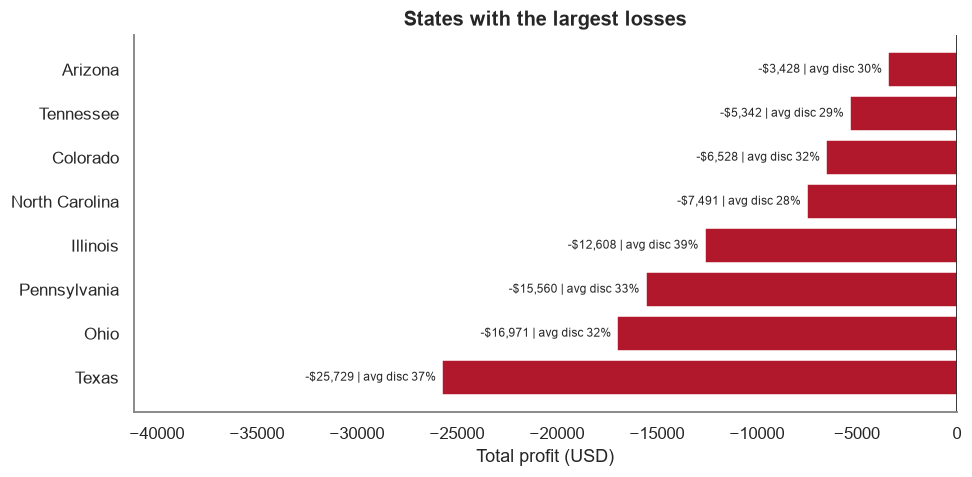

In [17]:
# Choropleth (geographic coordinate system): profit by state, diverging around 0
state = (df.groupby(["State", "State Code"], as_index=False)
           .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), AvgDiscount=("Discount", "mean")))
state["Margin %"] = (state["Profit"] / state["Sales"] * 100).round(1)
lim = state["Profit"].abs().max()

fig = px.choropleth(state, locations="State Code", locationmode="USA-states", scope="usa",
                    color="Profit", color_continuous_scale="RdBu", range_color=(-lim, lim),
                    hover_name="State", hover_data={"Sales": ":,.0f", "Margin %": True, "State Code": False},
                    title="Total profit by state — red states lose money")
fig.update_layout(height=520)
fig.write_html(f"{ASSETS}/10_profit_choropleth.html", include_plotlyjs="cdn")
fig.show()

# Static version of the worst states for the slide deck (horizontal bars, 0-baseline)
worst = state.nsmallest(8, "Profit").sort_values("Profit")
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#b2182b" if p < 0 else "#2166ac" for p in worst["Profit"]]
ax.barh(worst["State"], worst["Profit"], color=colors)
ax.axvline(0, color="black", lw=1)
ax.set(title="States with the largest losses", xlabel="Total profit (USD)")
for y, (p, d) in enumerate(zip(worst["Profit"], worst["AvgDiscount"])):
    ax.text(p, y, f"-${abs(p):,.0f} | avg disc {d:.0%}  ", va="center", ha="right", fontsize=8)
ax.set_xlim(worst["Profit"].min() * 1.6, 0)      # leave room for labels on the left
plt.tight_layout(); save(fig, "11_worst_states"); plt.show()

## 8. Polar coordinates for cyclical data
Months are cyclical (December wraps to January), so a **polar** chart is a natural coordinate system for seasonality.

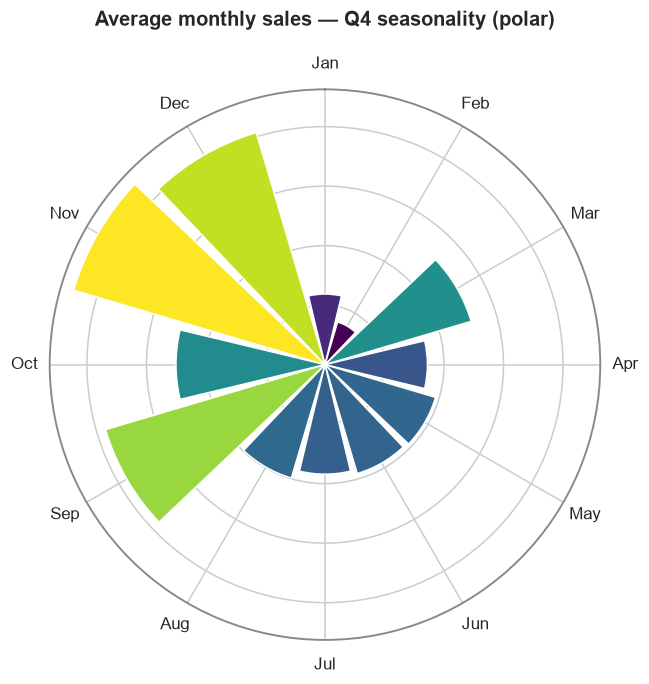

In [18]:
season = df.groupby("Month")["Sales"].sum() / df["Year"].nunique()      # average sales per calendar month
theta = np.linspace(0, 2 * np.pi, 12, endpoint=False)
width = 2 * np.pi / 12
norm = plt.Normalize(season.min(), season.max())

fig = plt.figure(figsize=(6.5, 6.5))
ax = fig.add_subplot(projection="polar")
ax.bar(theta, season.values, width=width * .9, color=plt.cm.viridis(norm(season.values)), bottom=0)
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.set_xticks(theta); ax.set_xticklabels(pd.date_range("2021-01-01", periods=12, freq="MS").strftime("%b"))
ax.set_yticklabels([])
ax.set_title("Average monthly sales — Q4 seasonality (polar)", pad=20)
save(fig, "12_polar_seasonality"); plt.show()

## 9. Key statistical findings for the story arc (Setup → Conflict → Resolution)

In [19]:
total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()
band = df.groupby("Discount Band", observed=True).agg(
    lines=("Sales", "size"), sales=("Sales", "sum"), profit=("Profit", "sum"),
    loss_rate=("Is Loss", "mean"))
band["margin %"] = (band["profit"] / band["sales"] * 100).round(1)
band["loss_rate"] = (band["loss_rate"] * 100).round(1)

high_disc = df[df["Discount"] > 0.2]
findings = {
    "Total sales (USD)": f"{total_sales:,.0f}",
    "Total profit (USD)": f"{total_profit:,.0f}",
    "Overall margin": f"{total_profit / total_sales:.1%}",
    f"Sales growth {yearly.index[0]}→{yearly.index[-1]}": f"{yearly['Sales'].iloc[-1] / yearly['Sales'].iloc[0] - 1:.0%}",
    "Order lines with a loss": f"{df['Is Loss'].mean():.1%}",
    "Profit lost on lines with discount > 20 %": f"{high_disc['Profit'].sum():,.0f}",
    "Loss-making sub-categories": ", ".join(sub.loc[sub['Profit'] < 0, 'Sub-Category']),
    "Top-3 loss states": ", ".join(state.nsmallest(3, 'Profit')['State']),
}
display(pd.Series(findings, name="value").to_frame())
band

,value
Total sales (USD),"2,297,201"
Total profit (USD),"286,397"
Overall margin,12.5%
Sales growth 2015→2018,51%
Order lines with a loss,18.7%
Profit lost on lines with discount > 20 %,"-135,376"
Loss-making sub-categories,"Bookcases, Tables, Supplies"
Top-3 loss states,"Texas, Ohio, Pennsylvania"


,lines,sales,profit,loss_rate,margin %
Discount Band,,,,,
0%,4798,1.087908e+06,320987.6032,0.0,29.5
1–20%,3803,8.465222e+05,100785.4745,13.8,11.9
21–40%,460,2.341379e+05,-35817.4655,90.2,-15.3
>40%,933,1.286323e+05,-99558.5905,100.0,-77.4


In [20]:
# What-if (resolution): cap discounts at 20 % for lines currently above 20 %.
# Conservative assumption: same units sold, price recovers to the 20 % discount level,
# unit cost unchanged. cost = sales - profit; list price = sales / (1 - discount).
sim = high_disc.copy()
sim["List Price Total"] = sim["Sales"] / (1 - sim["Discount"])
sim["Cost"] = sim["Sales"] - sim["Profit"]
sim["New Sales"] = sim["List Price Total"] * (1 - 0.20)
sim["New Profit"] = sim["New Sales"] - sim["Cost"]
uplift = sim["New Profit"].sum() - sim["Profit"].sum()
print(f"Estimated profit uplift if discounts are capped at 20%: ${uplift:,.0f}")
print(f"New overall margin: {(total_profit + uplift) / (total_sales - sim['Sales'].sum() + sim['New Sales'].sum()):.1%}"
      f"  (vs {total_profit / total_sales:.1%} today)")
print("Caveat: assumes demand does not drop when discounts are reduced — an upper bound.")

Estimated profit uplift if discounts are capped at 20%: $219,191
New overall margin: 20.1%  (vs 12.5% today)
Caveat: assumes demand does not drop when discounts are reduced — an upper bound.


## 10. Export the dashboard-ready dataset

In [21]:
# The BI dashboard (Power BI / Tableau / HTML) consumes this cleaned, enriched file.
export_cols = ["Row ID", "Order ID", "Order Date", "Ship Date", "Ship Days", "Ship Mode", "Customer ID",
               "Segment", "Regional Manager", "Returned", "City", "State", "State Code", "Postal Code", "Region", "Category",
               "Sub-Category", "Product Name", "Sales", "Quantity", "Discount", "Discount Band",
               "Profit", "Profit Margin", "Year", "Month"]
df[export_cols].to_csv(CLEAN_PATH, index=False)
# Also export the separate tables so Power BI / Tableau can rebuild the star schema with relationships
people.to_csv("../data/dim_people.csv", index=False)
returns.to_csv("../data/dim_returns.csv", index=False)
print("Saved", CLEAN_PATH, df[export_cols].shape)
print("Exported assets:", sorted(os.listdir(ASSETS)))

Saved ../data/clean_superstore.csv (9994, 26)
Exported assets: ['01_sales_distribution.png', '01_sales_distribution.svg', '02_margin_kde_by_category.png', '02_margin_kde_by_category.svg', '03_margin_by_discount_box_violin.png', '03_margin_by_discount_box_violin.svg', '04_profit_by_discount_ci.png', '04_profit_by_discount_ci.svg', '05_order_value_trend_ci.png', '05_order_value_trend_ci.svg', '06_correlation_heatmap.png', '06_correlation_heatmap.svg', '07_subcategory_bubble.html', '08_discount_vs_profit_scatter.html', '09_sales_treemap.html', '10_profit_choropleth.html', '11_worst_states.png', '11_worst_states.svg', '12_polar_seasonality.png', '12_polar_seasonality.svg', 'dashboard_screenshot_top.png']
